<a href="https://colab.research.google.com/github/dianahshimwa/probability-and-gradient-descent/blob/main/part4_gradient_descent/part4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np
from scipy.optimize import approx_fprime
import matplotlib.pyplot as plt

In [9]:
# 1. Initialize Matrices
X = np.array([[1.0, 3.0],
              [4.0, 10.0]])
y = np.array([5.0, 6.0])
m = np.array([-1.0, 2.0])
b = np.array([1.0, 1.0])
alpha = 0.01
n_updates = 3
N = len(y)

In [ ]:
## Building blocks
# Each function does one job, so nothing is repeated later.
# `compute_gradient` takes **any equation** and a point and returns its derivative using SciPy.

In [10]:
def predict(X, m, b):
    """y_hat = X.m + b"""
    return X @ m + b

def mse(y_hat, y):
    """J = (1/N) * sum((y_hat - y)^2)"""
    return np.mean((y_hat - y) ** 2)

def make_cost(X, y):
    """Return J as a function of one flat vector [m1, m2, b1, b2],
    which is the form SciPy needs for differentiation."""
    def cost(params):
        return mse(predict(X, params[:2], params[2:]), y)
    return cost

def compute_gradient(equation, point):
    """Numerical derivative of any equation, using SciPy."""
    eps = np.sqrt(np.finfo(float).eps)
    return approx_fprime(point, equation, eps)

def analytic_gradient(X, y, m, b):
    """Part 3 chain-rule gradient:
    dJ/dm = (2/N) X^T (y_hat - y),  dJ/db = (2/N)(y_hat - y)"""
    error = predict(X, m, b) - y
    return (2 / len(y)) * X.T @ error, (2 / len(y)) * error

cost = make_cost(X, y)

In [ ]:
## Check: does SciPy agree with our Part 3 derivation?
#Compare SciPy's numerical gradient with the chain-rule gradient at the starting point.

In [11]:
grad_scipy = compute_gradient(cost, np.concatenate((m, b)))
grad_m_hand, grad_b_hand = analytic_gradient(X, y, m, b)
grad_hand = np.concatenate((grad_m_hand, grad_b_hand))

print("SciPy gradient   :", grad_scipy)
print("Chain-rule (hand):", grad_hand)
print("Match?           :", np.allclose(grad_scipy, grad_hand, atol=1e-5))

SciPy gradient   : [ 45.         113.00000095   1.          11.        ]
Chain-rule (hand): [ 45. 113.   1.  11.]
Match?           : True


In [ ]:
## Gradient descent
#Every step is printed: predictions, error, gradients, updated parameters and cost.
#Update rule: `new = old − α × gradient`

In [12]:
def update_params(m, b, grad_m, grad_b, alpha):
    """new = old - alpha * gradient"""
    return m - alpha * grad_m, b - alpha * grad_b

def gradient_descent(X, y, m, b, alpha, n_updates, verbose=True):
    cost = make_cost(X, y)
    history = {"m": [m.copy()], "b": [b.copy()],
               "J": [cost(np.concatenate((m, b)))]}

    for i in range(1, n_updates + 1):
        y_hat = predict(X, m, b)
        error = y_hat - y
        grads = compute_gradient(cost, np.concatenate((m, b)))
        grad_m, grad_b = grads[:2], grads[2:]
        m, b = update_params(m, b, grad_m, grad_b, alpha)

        history["m"].append(m.copy())
        history["b"].append(b.copy())
        history["J"].append(cost(np.concatenate((m, b))))

        if verbose:
            print(f"--- Update {i} ---")
            print(f"  y_hat      = {np.round(y_hat, 4)}")
            print(f"  error      = {np.round(error, 4)}")
            print(f"  J (before) = {mse(y_hat, y):.4f}")
            print(f"  dJ/dm      = {np.round(grad_m, 4)}")
            print(f"  dJ/db      = {np.round(grad_b, 4)}")
            print(f"  new m      = {np.round(m, 4)}")
            print(f"  new b      = {np.round(b, 4)}")
            print(f"  J (after)  = {history['J'][-1]:.4f}\n")
    return m, b, history

In [14]:
m_final, b_final, history = gradient_descent(X, y, m, b, alpha, n_updates)

--- Update 1 ---
  y_hat      = [ 6. 17.]
  error      = [ 1. 11.]
  J (before) = 61.0000
  dJ/dm      = [ 45. 113.]
  dJ/db      = [ 1. 11.]
  new m      = [-1.45  0.87]
  new b      = [0.99 0.89]
  J (after)  = 6.5033

--- Update 2 ---
  y_hat      = [2.15 3.79]
  error      = [-2.85 -2.21]
  J (before) = 6.5033
  dJ/dm      = [-11.69 -30.65]
  dJ/db      = [-2.85 -2.21]
  new m      = [-1.3331  1.1765]
  new b      = [1.0185 0.9121]
  J (after)  = 2.4974

--- Update 3 ---
  y_hat      = [3.2149 7.3447]
  error      = [-1.7851  1.3447]
  J (before) = 2.4974
  dJ/dm      = [3.5937 8.0917]
  dJ/db      = [-1.7851  1.3447]
  new m      = [-1.369   1.0956]
  new b      = [1.0364 0.8987]
  J (after)  = 2.1645



In [ ]:
## Plots
# One reusable plotting function draws both figures.

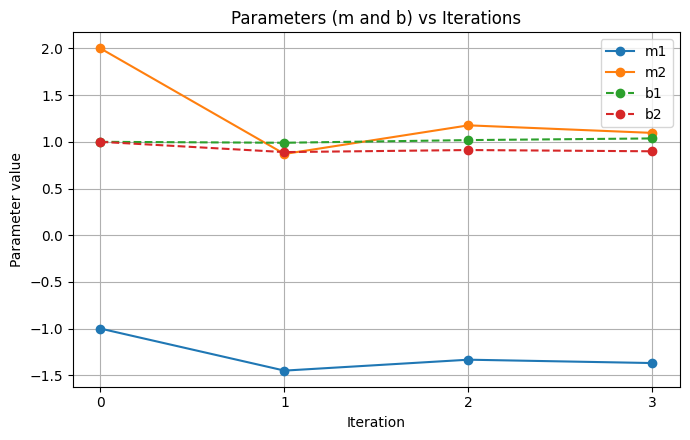

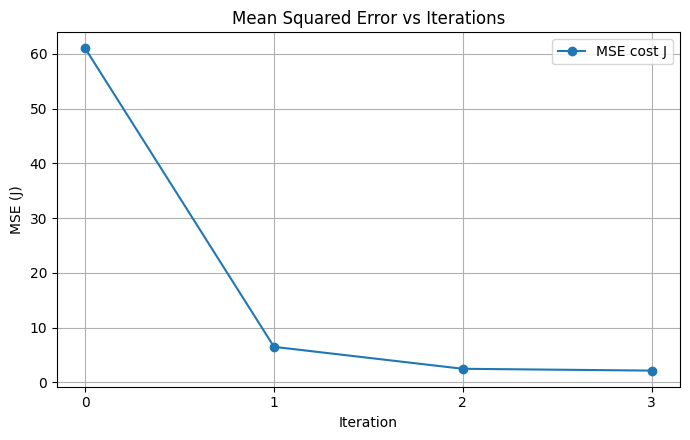

In [15]:
def plot_series(series, labels, title, ylabel, styles=None):
    """Reusable line plot for iteration histories."""
    steps = range(len(series[0]))
    plt.figure(figsize=(7, 4.5))
    for k, (values, label) in enumerate(zip(series, labels)):
        plt.plot(steps, values, marker="o",
                 linestyle=(styles[k] if styles else "-"), label=label)
    plt.xticks(steps)
    plt.title(title)
    plt.xlabel("Iteration")
    plt.ylabel(ylabel)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

m_arr, b_arr = np.array(history["m"]), np.array(history["b"])

# Plot 1: how m and b change
plot_series([m_arr[:, 0], m_arr[:, 1], b_arr[:, 0], b_arr[:, 1]],
            ["m1", "m2", "b1", "b2"],
            "Parameters (m and b) vs Iterations", "Parameter value",
            styles=["-", "-", "--", "--"])

# Plot 2: how the error changes (separate figure)
plot_series([history["J"]], ["MSE cost J"],
            "Mean Squared Error vs Iterations", "MSE (J)")

In [ ]:
## Trend
# - **m** does not move in one direction. Update 1 is a big jump (m₂: 2 → 0.87) because the starting gradient was large ([45, 113]). It overshoots, so m₂ bounces back to 1.18, then settles at 1.10. The steps shrink each time (1.13, 0.31, 0.08).
# - **b** barely moves because ∂J/∂b = (2/N)(ŷ − y) has no feature multiplier, while ∂J/∂m = (2/N)Xᵀ(ŷ − y) does.
# - **Error** falls 61 → 6.50 → 2.50 → 2.16, so each update reduces the cost. Three updates are not enough to converge: the final predictions are [2.95, 6.38] against targets [5, 6].

In [ ]:
## Manual (Part 3) vs code (Part 4)

In [17]:
manual = {
    1: (np.array([-1.45, 0.87]),     np.array([0.99, 0.89]),     6.5033),
    2: (np.array([-1.3331, 1.1765]), np.array([1.0185, 0.9121]), 2.4974),
    3: (np.array([-1.3690, 1.0956]), np.array([1.0364, 0.8987]), 2.1645),
}

print(f"{'Update':<8}{'Matches handwritten (4 dp)?'}")
for i, (m_h, b_h, J_h) in manual.items():
    ok = (np.allclose(history["m"][i], m_h, atol=1e-4)
          and np.allclose(history["b"][i], b_h, atol=1e-4)
          and abs(history["J"][i] - J_h) < 1e-4)
    print(f"{i:<8}{ok}")

Update  Matches handwritten (4 dp)?
1       True
2       True
3       True
